<a href="https://colab.research.google.com/github/Janani-Hendeniya/EN3160-Assignment-02/blob/main/230238R_a02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3160 Assignment 02 - Fitting and Alignment

## Question 1: Blob Detection Using LoG

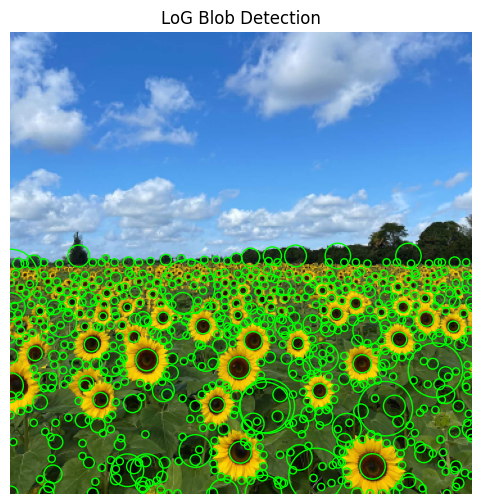

Detected circles: 657
Sigma range: 2 to 15


In [18]:

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter

# Load image and convert to grayscale
image = cv.imread("the_berry_farms_sunflower_field.jpeg",
                  cv.IMREAD_REDUCED_COLOR_4)

if image is None:
    raise FileNotFoundError("Sunflower image not found")

gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(float)
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

# Build scale-normalized LoG scale-space for dark blobs
sigmas = np.arange(2, 16)

scale_space = np.stack([
    np.maximum(s**2 * gaussian_laplace(gray, sigma=s), 0)
    for s in sigmas
])

# Detect 3D local maxima above threshold
maxima = maximum_filter(scale_space, size=(3, 3, 3))
mask = (scale_space == maxima) & (
    scale_space > 0.15 * scale_space.max()
)

# Extract circles below the horizon
horizon = int(gray.shape[0] * 0.48)
circles = []

for k, y, x in np.argwhere(mask):
    if y >= horizon:
        circles.append((x, y, np.sqrt(2) * sigmas[k]))

# Display detected circles
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(image_rgb)

for x, y, r in circles:
    ax.add_patch(plt.Circle((x, y), r,
                            fill=False, color="lime", lw=1))

ax.set_title("LoG Blob Detection")
ax.axis("off")
plt.show()

print("Detected circles:", len(circles))
print("Sigma range:", sigmas[0], "to", sigmas[-1])


Reporting largest circles

In [17]:

# Report 10 largest detected circles
largest = sorted(circles, key=lambda c: c[2], reverse=True)[:10]

print("Largest detected circles (pixels):")
print("No.    X     Y     Radius     Sigma")

for i, (x, y, r) in enumerate(largest, 1):
    print(f"{i:<6} {x:<5} {y:<5} {r:>7.2f} {r/np.sqrt(2):>9.2f}")


Largest detected circles (pixels):
No.    X     Y     Radius     Sigma
1      0     190     21.21     15.00
2      138   198     21.21     15.00
3      331   263     21.21     15.00
4      200   291     21.21     15.00
5      292   293     21.21     15.00
6      238   345     21.21     15.00
7      198   292     19.80     14.00
8      197   359     14.14     10.00
9      144   326     12.73      9.00
10     91    341     12.73      9.00


Methodology

The sunflower field image was converted to grayscale, and scale-normalized Laplacian of Gaussian (LoG) filtering was applied over a range of $\sigma = 2$ to $15$, with a step size of $1$. Positive LoG responses were retained to detect dark-centred blobs. Local maxima were identified in the three-dimensional scale-space using a $3 \times 3 \times 3$ neighbourhood, with a response threshold of 15% of the maximum response. A spatial mask was applied to exclude the sky region.

Results

Detected blob centres were represented by circles with radii calculated using:

$$r = \sqrt{2}\sigma$$

The resulting circles had radii ranging from approximately 2.83 to 21.21 pixels. The largest detected circles were identified based on their estimated radii.

Discussion

The detector identified many dark sunflower centres, although some false detections occurred around leaves, background vegetation, and other dark regions. Restricting detections to the lower portion of the image reduced unwanted sky detections. However, the method remains sensitive to the selected scale range and response threshold.

# Question 2: Line and Circle Fitting Using RANSAC

## Part A: Generating the Noisy Point Set

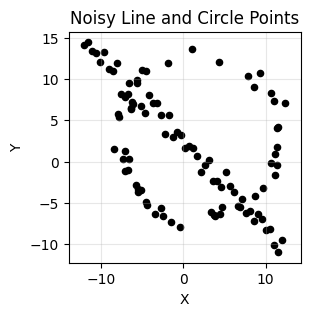

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(0)

N = 100
half_n = N // 2

# Generate noisy circle points
r, x0_gt, y0_gt = 10, 2, 3
t = np.random.uniform(0, 2*np.pi, half_n)
noise = (r/16) * np.random.randn(half_n)

X_circ = np.column_stack((
    x0_gt + (r + noise) * np.cos(t),
    y0_gt + (r + noise) * np.sin(t)
))

# Generate noisy line points
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + np.random.randn(half_n)

X_line = np.column_stack((x, y))

# Combine both point sets
X = np.vstack((X_circ, X_line))

# Visualize the noisy dataset
plt.figure(figsize=(3, 3))
plt.scatter(X[:, 0], X[:, 1], s=20, c="black")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Noisy Line and Circle Points")
plt.axis("equal")
plt.grid(alpha=0.3)
plt.show()


## Question 2(a): RANSAC Line Fitting

In [60]:
# Question 2(a): RANSAC Line Fitting

# Construct a normalized line ax + by = d from two points
def line_from_points(p1, p2):
    dx, dy = p2 - p1
    length = np.hypot(dx, dy)

    if length < 1e-12:
        return None

    a, b = -dy / length, dx / length
    d = a * p1[0] + b * p1[1]
    return np.array([a, b, d])


# Calculate perpendicular distances to a normalized line
def line_errors(points, line):
    a, b, d = line
    return np.abs(a * points[:, 0] + b * points[:, 1] - d)


# RANSAC line fitting from scratch
def ransac_line(points, iterations=1000,
                threshold=1.5, min_inliers=35):

    rng = np.random.default_rng(42)
    best_line, best_inliers, best_sample = None, None, None
    best_count = 0

    for _ in range(iterations):
        sample = points[rng.choice(len(points), 2, replace=False)]
        candidate = line_from_points(sample[0], sample[1])

        if candidate is None:
            continue

        inliers = line_errors(points, candidate) < threshold
        count = np.sum(inliers)

        if count > best_count:
            best_count = count
            best_line = candidate
            best_inliers = inliers
            best_sample = sample.copy()

    if best_count < min_inliers:
        raise ValueError("No line has enough inliers")

    return best_line, best_inliers, best_sample


# Refine line using Total Least Squares (TLS)
def fit_line_tls(points):
    center = points.mean(axis=0)
    _, _, vh = np.linalg.svd(points - center)

    a, b = vh[-1]
    d = a * center[0] + b * center[1]

    return np.array([a, b, d])


# Run RANSAC and refine using line inliers
best_line, line_inliers, line_sample = ransac_line(X)
refined_line = fit_line_tls(X[line_inliers])

print("RANSAC line:", best_line)
print("Refined TLS line:", refined_line)
print("Line inliers:", np.sum(line_inliers))
print("Normal length:", np.linalg.norm(refined_line[:2]))


RANSAC line: [0.69877621 0.71534035 1.6715574 ]
Refined TLS line: [0.71564883 0.69846028 1.56177478]
Line inliers: 57
Normal length: 0.9999999999999999


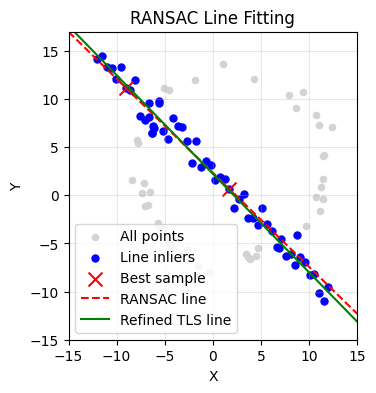

In [62]:
# Visualize RANSAC line fitting

fig, ax = plt.subplots(figsize=(4, 4))

# Plot all points and line inliers
ax.scatter(X[:, 0], X[:, 1], c="lightgray", s=20, label="All points")
ax.scatter(X[line_inliers, 0], X[line_inliers, 1],
           c="blue", s=25, label="Line inliers")

# Highlight the best sample
ax.scatter(line_sample[:, 0], line_sample[:, 1],
           c="red", marker="x", s=100, label="Best sample")

# Draw sampled and refined lines
x_vals = np.linspace(-15, 15, 200)

for line, color, style, label in [
    (best_line, "red", "--", "RANSAC line"),
    (refined_line, "green", "-", "Refined TLS line")
]:
    a, b, d = line

    if abs(b) > 1e-10:
        ax.plot(x_vals, (d - a*x_vals)/b,
                color=color, linestyle=style, label=label)
    else:
        ax.axvline(d/a, color=color, linestyle=style, label=label)

ax.set(xlim=(-15, 15), ylim=(-15, 17),
       title="RANSAC Line Fitting", xlabel="X", ylabel="Y")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


## Question 2(b): Circle Fitting Using RANSAC

Line inliers removed: 57
Remaining points: 43


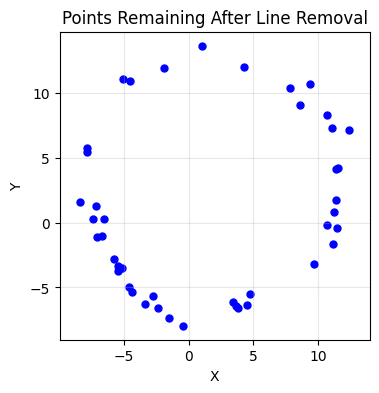

RANSAC circle [cx, cy, r]: [ 1.9256625   3.126726   10.14596468]
Circle inliers: 43


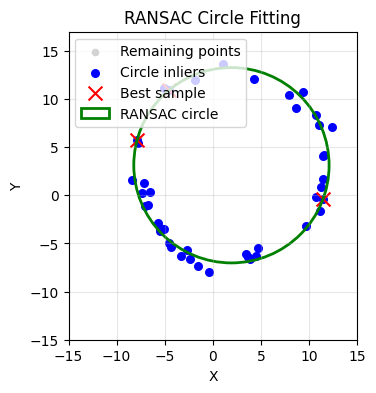

Refined circle [cx, cy, r]: [1.86959015 3.06549708 9.94929261]
Ground truth [cx, cy, r]: [2, 3, 10]


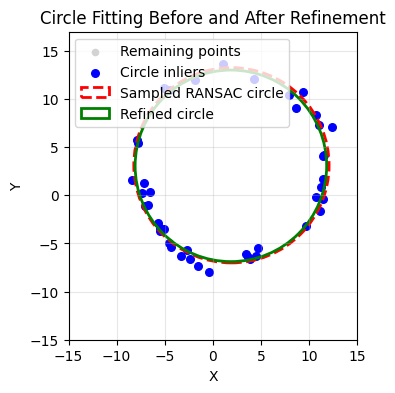

In [64]:
# Question 2(b): RANSAC Circle Fitting

# Remove line inliers
X_remaining = X[~line_inliers]

print(f"Line inliers removed: {line_inliers.sum()}")
print(f"Remaining points: {len(X_remaining)}")

# Visualize remaining points
plt.figure(figsize=(4, 4))
plt.scatter(X_remaining[:, 0], X_remaining[:, 1],
            c="blue", s=25)
plt.title("Points Remaining After Line Removal")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid(alpha=0.3)
plt.show()


# Fit a circle through three points
def circle_from_points(p1, p2, p3):
    A = 2 * np.array([p2 - p1, p3 - p1])
    B = np.array([
        np.dot(p2, p2) - np.dot(p1, p1),
        np.dot(p3, p3) - np.dot(p1, p1)
    ])

    if abs(np.linalg.det(A)) < 1e-8:
        return None

    center = np.linalg.solve(A, B)
    radius = np.linalg.norm(p1 - center)
    return np.array([*center, radius])


# Calculate radial errors
def circle_errors(points, circle):
    cx, cy, r = circle
    return np.abs(np.linalg.norm(points - [cx, cy], axis=1) - r)


# Circle RANSAC implemented from scratch
def ransac_circle(points, iterations=2000,
                  threshold=1.25, min_inliers=25):

    rng = np.random.default_rng(42)
    best_circle, best_inliers, best_sample = None, None, None
    best_count = 0

    for _ in range(iterations):
        sample = points[rng.choice(len(points), 3, replace=False)]
        candidate = circle_from_points(*sample)

        if candidate is None:
            continue

        inliers = circle_errors(points, candidate) < threshold
        count = inliers.sum()

        if count > best_count:
            best_count = count
            best_circle = candidate
            best_inliers = inliers
            best_sample = sample.copy()

    if best_count < min_inliers:
        raise ValueError("No circle has enough inliers")

    return best_circle, best_inliers, best_sample


# Estimate circle using remaining points
best_circle, circle_inliers, circle_sample = ransac_circle(X_remaining)
circle_points = X_remaining[circle_inliers]

print("RANSAC circle [cx, cy, r]:", best_circle)
print("Circle inliers:", circle_inliers.sum())


# Visualize RANSAC circle and best sample
fig, ax = plt.subplots(figsize=(4, 4))

ax.scatter(X_remaining[:, 0], X_remaining[:, 1],
           c="lightgray", s=20, label="Remaining points")
ax.scatter(circle_points[:, 0], circle_points[:, 1],
           c="blue", s=30, label="Circle inliers")
ax.scatter(circle_sample[:, 0], circle_sample[:, 1],
           c="red", marker="x", s=100, label="Best sample")

ax.add_patch(plt.Circle(
    best_circle[:2], best_circle[2],
    fill=False, color="green", lw=2, label="RANSAC circle"
))

ax.set(xlim=(-15, 15), ylim=(-15, 17),
       title="RANSAC Circle Fitting", xlabel="X", ylabel="Y")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


# Refine circle using all RANSAC inliers
def circle_objective(params, points):
    cx, cy, r = params
    return np.sum(
        (np.linalg.norm(points - [cx, cy], axis=1) - r)**2
    )


result = minimize(
    circle_objective,
    best_circle,
    args=(circle_points,),
    bounds=[(None, None), (None, None), (1e-8, None)]
)

if not result.success:
    print("Optimization warning:", result.message)

refined_circle = result.x

print("Refined circle [cx, cy, r]:", refined_circle)
print("Ground truth [cx, cy, r]: [2, 3, 10]")


# Visualize RANSAC circle vs. refined circle
fig, ax = plt.subplots(figsize=(4, 4))

ax.scatter(X_remaining[:, 0], X_remaining[:, 1],
           c="lightgray", s=20, label="Remaining points")
ax.scatter(circle_points[:, 0], circle_points[:, 1],
           c="blue", s=30, label="Circle inliers")

ax.add_patch(plt.Circle(
    best_circle[:2], best_circle[2],
    fill=False, color="red", linestyle="--",
    lw=2, label="Sampled RANSAC circle"
))

ax.add_patch(plt.Circle(
    refined_circle[:2], refined_circle[2],
    fill=False, color="green",
    lw=2, label="Refined circle"
))

ax.set(xlim=(-15, 15), ylim=(-15, 17),
       title="Circle Fitting Before and After Refinement",
       xlabel="X", ylabel="Y")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend()
plt.show()


## Question 2(c)

In [65]:
# Draw a line represented by ax + by = d
def draw_line(ax, line, color, label, style="-"):
    a, b, d = line

    if abs(b) > 1e-10:
        x = np.linspace(-15, 15, 200)
        ax.plot(x, (d - a*x)/b, color=color,
                linestyle=style, lw=2, label=label)
    else:
        ax.axvline(d/a, color=color,
                   linestyle=style, lw=2, label=label)


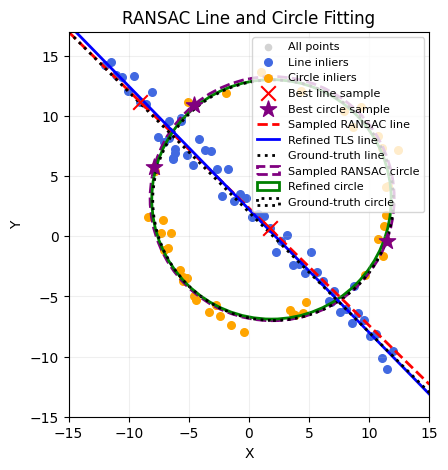

Line inliers: 57
Circle inliers: 43
Line mean perpendicular error: 0.6278
Circle mean radial error: 0.4670


In [67]:
# Question 2(c): Combined RANSAC visualization

fig, ax = plt.subplots(figsize=(5, 5))
circle_points = X_remaining[circle_inliers]

# Plot all points and model inliers
ax.scatter(X[:, 0], X[:, 1], c="lightgray",
           s=20, label="All points")
ax.scatter(X[line_inliers, 0], X[line_inliers, 1],
           c="royalblue", s=30, label="Line inliers")
ax.scatter(circle_points[:, 0], circle_points[:, 1],
           c="orange", s=30, label="Circle inliers")

# Highlight the RANSAC samples
ax.scatter(line_sample[:, 0], line_sample[:, 1],
           c="red", marker="x", s=110,
           label="Best line sample", zorder=5)
ax.scatter(circle_sample[:, 0], circle_sample[:, 1],
           c="purple", marker="*", s=150,
           label="Best circle sample", zorder=5)

# Draw sampled, refined and ground-truth lines
gt_line = np.array([1/np.sqrt(2), 1/np.sqrt(2), np.sqrt(2)])

draw_line(ax, best_line, "red", "Sampled RANSAC line", "--")
draw_line(ax, refined_line, "blue", "Refined TLS line")
draw_line(ax, gt_line, "black", "Ground-truth line", ":")

# Draw sampled, refined and ground-truth circles
for circle, color, style, label in [
    (best_circle, "purple", "--", "Sampled RANSAC circle"),
    (refined_circle, "green", "-", "Refined circle"),
    ([2, 3, 10], "black", ":", "Ground-truth circle")
]:
    ax.add_patch(plt.Circle(
        circle[:2], circle[2], fill=False,
        color=color, linestyle=style,
        lw=2, label=label
    ))

ax.set(xlim=(-15, 15), ylim=(-15, 17),
       xlabel="X", ylabel="Y",
       title="RANSAC Line and Circle Fitting")
ax.set_aspect("equal")
ax.grid(alpha=0.2)
ax.legend(fontsize=8, loc="upper right")

# Save and display the completed figure
plt.savefig("question2_ransac_result.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Calculate mean fitting errors
line_mae = np.mean(line_errors(X[line_inliers], refined_line))
circle_mae = np.mean(circle_errors(circle_points, refined_circle))

print(f"Line inliers: {line_inliers.sum()}")
print(f"Circle inliers: {circle_inliers.sum()}")
print(f"Line mean perpendicular error: {line_mae:.4f}")
print(f"Circle mean radial error: {circle_mae:.4f}")


## Question 2(d): Effect of Fitting the Circle First

Refined circle-first model: [1.95209415 3.0538569  9.91503381]
Refined line-second model: [-0.72315757 -0.69068309 -1.66383996]


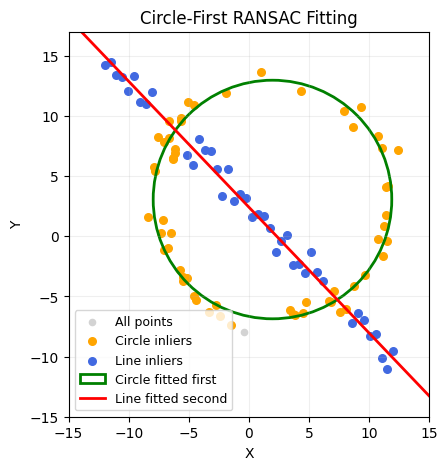

In [70]:
# Question 2(d): Circle-first RANSAC fitting

# Fit circle first and remove its inliers
circle_first, circle_first_inliers, circle_first_sample = ransac_circle(
    X, iterations=2000, threshold=1.25, min_inliers=25
)
X_after_circle = X[~circle_first_inliers]

# Fit line to the remaining points
line_second, line_second_inliers, line_second_sample = ransac_line(
    X_after_circle, iterations=1000, threshold=1.5, min_inliers=35
)

# Refine both models
circle_first_points = X[circle_first_inliers]

result = minimize(
    circle_objective, circle_first,
    args=(circle_first_points,),
    bounds=[(None, None), (None, None), (1e-8, None)]
)
if not result.success:
    print("Optimization warning:", result.message)

refined_circle_first = result.x
refined_line_second = fit_line_tls(X_after_circle[line_second_inliers])

print("Refined circle-first model:", refined_circle_first)
print("Refined line-second model:", refined_line_second)

# Visualize circle-first fitting
fig, ax = plt.subplots(figsize=(5, 5))

ax.scatter(X[:, 0], X[:, 1],
           c="lightgray", s=20, label="All points")
ax.scatter(X[circle_first_inliers, 0], X[circle_first_inliers, 1],
           c="orange", s=30, label="Circle inliers")
ax.scatter(X_after_circle[line_second_inliers, 0],
           X_after_circle[line_second_inliers, 1],
           c="royalblue", s=30, label="Line inliers")

ax.add_patch(plt.Circle(
    refined_circle_first[:2], refined_circle_first[2],
    fill=False, color="green", lw=2, label="Circle fitted first"
))
draw_line(ax, refined_line_second, "red", "Line fitted second")

ax.set(xlim=(-15, 15), ylim=(-15, 17),
       title="Circle-First RANSAC Fitting", xlabel="X", ylabel="Y")
ax.set_aspect("equal")
ax.grid(alpha=0.2)
ax.legend(fontsize=9)
plt.show()


In [69]:
# Compare fitting orders against ground truth

def evaluate_models(line, circle):
    cx, cy, r = circle
    return [
        np.mean(line_errors(X_line, line)),
        np.linalg.norm([cx - 2, cy - 3]),
        abs(r - 10)
    ]

line_first_eval = evaluate_models(refined_line, refined_circle)
circle_first_eval = evaluate_models(refined_line_second, refined_circle_first)

print(f"{'Metric':<25}{'Line-first':>14}{'Circle-first':>15}")
print("-" * 54)

metrics = ["Line mean error", "Circle center error", "Circle radius error"]

for name, a, b in zip(metrics, line_first_eval, circle_first_eval):
    print(f"{name:<25}{a:>14.4f}{b:>15.4f}")

print("\nInlier counts:")
print(f"Line-first:   Line = {line_inliers.sum()}, Circle = {circle_inliers.sum()}")
print(f"Circle-first: Line = {line_second_inliers.sum()}, Circle = {circle_first_inliers.sum()}")


Metric                       Line-first   Circle-first
------------------------------------------------------
Line mean error                  0.5502         0.5488
Circle center error              0.1459         0.0721
Circle radius error              0.0507         0.0850

Inlier counts:
Line-first:   Line = 57, Circle = 43
Circle-first: Line = 41, Circle = 58


### Question 2(d): Effect of Fitting the Circle First

To investigate the effect of fitting order, RANSAC was first applied to the complete point set to estimate the circle. The circle inliers were then removed, and line RANSAC was applied to the remaining points.

The fitting order affects the consensus sets because points near the intersection of the line and circle may be classified as inliers for either model. Removing these points during the first fitting stage changes the data available for estimating the second model.

The results demonstrate that sequential RANSAC fitting can be sensitive to:
- **Model fitting order**
- **Noise in the dataset**
- **Selected inlier thresholds**


# Question 3: Homography and Image Blending

## Example 1: Superimposing a Flag on a Building


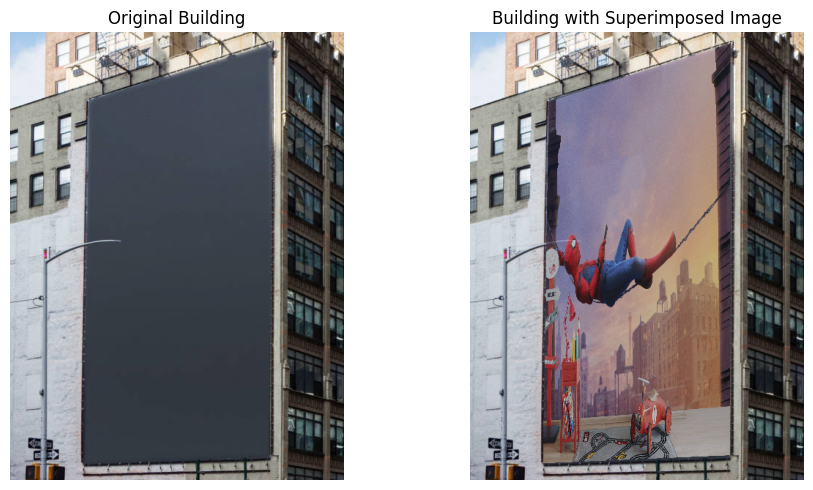

Homography matrix:
 [[ 8.14261685e-02 -5.85078271e-03  1.07000000e+02]
 [-3.26040128e-02  2.59541754e-01  9.46500015e+01]
 [-4.90647677e-05 -1.51813800e-05  1.00000000e+00]]


In [82]:
# Question 3: Homography and Image Blending (Example 1)

# Load background and overlay images
building = cv.imread("building.jpg")
overlay = cv.imread("flag.jpg")

if building is None or overlay is None:
    raise FileNotFoundError("Check the input image filenames.")

# Selected corners of the billboard (TL, TR, BR, BL)
dst_points = np.float32([
    [107.00,  94.65],
    [355.00,  14.65],
    [354.00, 577.65],
    [ 99.00, 588.65]
])

# Define the corresponding corners of the overlay
h, w = overlay.shape[:2]
src_points = np.float32([
    [0, 0], [w-1, 0],
    [w-1, h-1], [0, h-1]
])

# Calculate homography and warp the overlay
H = cv.getPerspectiveTransform(src_points, dst_points)
height, width = building.shape[:2]

warped = cv.warpPerspective(overlay, H, (width, height))

# Warp an all-white mask to identify the overlay region
mask = np.full((h, w), 255, dtype=np.uint8)
warped_mask = cv.warpPerspective(mask, H, (width, height))

# Alpha blending within the selected region
alpha = 0.7
weight = (warped_mask / 255.0)[:, :, None] * alpha

result = (
    weight * warped.astype(float) +
    (1 - weight) * building.astype(float)
).astype(np.uint8)

# Display original and final images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, img, title in zip(
    axes,
    [building, result],
    ["Original Building", "Building with Superimposed Image"]
):
    ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Homography matrix:\n", H)


## Question 3: Example 2 - Portrait on a Stone Wall

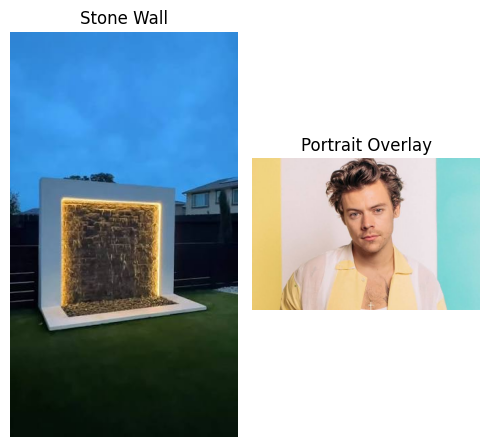

Selected destination points:
[[ 76.   247.65]
 [218.   257.65]
 [215.   389.65]
 [ 76.   403.65]]


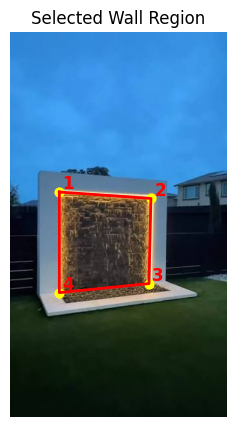

Homography matrix:
[[2.69169089e-01 4.30813652e-03 7.60000000e+01]
 [8.49986337e-02 3.68779310e-01 2.47649994e+02]
 [2.72569712e-04 5.66860069e-05 1.00000000e+00]]


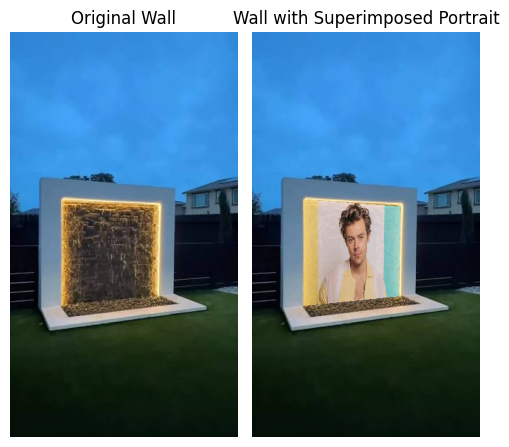

In [96]:
# Question 3: Example 2 - Portrait on a Stone Wall

# Load images
wall2 = cv.imread("wall2.jpg")
overlay2 = cv.imread("flag2.jpg")

if wall2 is None or overlay2 is None:
    raise FileNotFoundError("Check the image filenames.")

# Convert to RGB for display
wall2_rgb = cv.cvtColor(wall2, cv.COLOR_BGR2RGB)
overlay2_rgb = cv.cvtColor(overlay2, cv.COLOR_BGR2RGB)

# Show the input images
fig, axes = plt.subplots(1, 2, figsize=(5, 5))

axes[0].imshow(wall2_rgb)
axes[0].set_title("Stone Wall")
axes[0].axis("off")

axes[1].imshow(overlay2_rgb)
axes[1].set_title("Portrait Overlay")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Selected destination points on the stone wall
# Order: top-left, top-right, bottom-right, bottom-left
dst_points2 = np.float32([
    [76.00, 247.65],
    [218.00, 257.65],
    [215.00, 389.65],
    [76.00, 403.65]
])

print("Selected destination points:")
print(dst_points2)

# Optional: visualize selected region
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(wall2_rgb)

polygon = np.vstack((dst_points2, dst_points2[0]))
ax.plot(polygon[:, 0], polygon[:, 1], "r-", linewidth=2)

for i, (x, y) in enumerate(dst_points2, start=1):
    ax.scatter(x, y, color="yellow", s=40)
    ax.text(x + 5, y - 5, str(i),
            color="red", fontsize=12, fontweight="bold")

ax.set_title("Selected Wall Region")
ax.axis("off")
plt.show()

# Define source points from the overlay image
h, w = overlay2.shape[:2]
src_points2 = np.float32([
    [0, 0],
    [w - 1, 0],
    [w - 1, h - 1],
    [0, h - 1]
])

# Compute homography
H2 = cv.getPerspectiveTransform(src_points2, dst_points2)

print("Homography matrix:")
print(H2)

# Warp the overlay image
height2, width2 = wall2.shape[:2]
warped2 = cv.warpPerspective(overlay2, H2, (width2, height2))

# Create and warp mask
mask2 = np.full((h, w), 255, dtype=np.uint8)
warped_mask2 = cv.warpPerspective(mask2, H2, (width2, height2))

# Blend overlay with the wall
alpha2 = 0.85
weight2 = (warped_mask2.astype(np.float32) / 255.0)[:, :, None] * alpha2

result2 = (
    weight2 * warped2.astype(np.float32) +
    (1 - weight2) * wall2.astype(np.float32)
).astype(np.uint8)

# Show final result
fig, axes = plt.subplots(1, 2, figsize=(5, 5))

axes[0].imshow(wall2_rgb)
axes[0].set_title("Original Wall")
axes[0].axis("off")

axes[1].imshow(cv.cvtColor(result2, cv.COLOR_BGR2RGB))
axes[1].set_title("Wall with Superimposed Portrait")
axes[1].axis("off")

plt.tight_layout()
plt.show()